### Laboratorium 4, cześć 2: Transformacja Hougha

#### _Fabuła_
_Budujemy aplikację do szkolenia snookerzystów. Jej celem będzie, między innymi, analiza pozycji i sugerowanie zagrań. Naturalnie, podstawą działania aplikacji musi być funkcjonalność detekcji bil i określenia ich pozycji w układzie współrzędnych stołu. W dalszych etapach określane będą geometryczne relacje między bilami i łuzami - ich implementacją zajmie się jednak inny zespół._

#### Zadanie
Twoim celem będzie wykonanie detekcji **bil** oraz **band** za pomocą transformacji Hougha.
Przygotujesz potok przetwarzania przyjmujący obraz kolorowy w przestrzeni BGR/RGB a zwracający dwie kolekcje: jedną reprezentującą okręgi (bile), drugą - linie/odcinki (bandy) lub punkty (narożniki stołu).
Format tych kolekcji jest dowolny, szczegóły implementacji potoku podobnie.
W ogólności, potok powinien składać się z:
* etapu przetwarzania wstępnego - skorzystaj ze swojego ulubionego detektora krawędzi,
* wykonania transformacji Hougha dla linii ([`cv2.HoughLines`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga0b7ee275f89bb1a799ab70a42131f39d)) do wykrycia band,
* wykonania transformacji Hougha dla okręgów ([`cv2.HoughCircles`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga47849c3be0d0406ad3ca45db65a25d2d)) do wykrycia bil,
* przetwarzania końcowego wyników transformacji (np. usunięcie nadmiarowych/fałszywych detekcji).

Zaimplementuj również funkcję prezentującą wyniki w formie wizualnej, tj. rysującej wykryte obiekty na kopii obrazu wejściowego.

Dane są cztery obrazy.
Staraj się prowadzić eksperymenty na jednym czy dwóch, a następnie zaprezentować wyniki na pozostałych.

#### Oczekiwane rezultaty
1. Zacznij od znalezienia odpowiednich parametrów detektora krawędzi - jeśli na tym etapie wyniki będą słabe, to dalej będzie tylko gorzej (_garbage-in, garbage-out_). Nie skupiaj się na badaniu ich wpływu na wyniki końcowe, a jedynie przedstaw efekt przetwarzania wstępnego, tj. jak wygląda obraz, na którym wykonywana będzie TH. Ta część zadania będzie oceniana binarnie: dobrze/źle.
2. Kalibracja parametrów transformacji Hougha: zadanie **NIE** polega na zrobieniu grid searchu po parametrach TH (wykonanie go nie jest _zabronione_, po prostu nie umieszczaj go w notatniku). Interesujące jest jedynie zrozumienie działania poszczególnych parametrów i ich wpływu na wyniki - pozostaw w notatniku jedynie kilka przykładowych wyników, takich które ilustrują dokonane przez Ciebie wybory parametrów (_ustawiam parametr $x$ na wartość $x_0$, bo przy wartości $x_1$ działo się tak a tak_).
3. Demonstracja wyników na pozostałych obrazach: przedstaw obraz wejściowy, wykryte krawędzie, wykryte obiekty. Efektem powinny być 4 (lub 6) linii reprezentujących bandy, oraz zbiór okręgów odpowiadających bilom (w idealnym przypadku 1:1, ale nie musisz poświęcać długich godzin na wyeliminowaniu _wszystkich_ błędów, ważniejsze jest by umieć wyjaśnić, skąd się wzięły).


#### Literatura
1. Dokumentacja funkcji([`cv2.HoughLines`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga0b7ee275f89bb1a799ab70a42131f39d)) i ([`cv2.HoughCircles`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga47849c3be0d0406ad3ca45db65a25d2d)) - działanie parametrów jest bardzo dobrze opisane.
2. Jeśli chcesz poznać TH "od środka" - [tutaj](https://medium.com/@alb.formaggio/implementing-the-hough-transform-from-scratch-09a56ba7316b) ktoś zaimplementował ją od zera. Czytając, uważaj tylko, by nie powtórzyć po Alberto jego błędu (krawędzie!)
3. Źródło danych do zadania: kompilacja [TOP 40 SHOTS of 2025 British Open](https://www.youtube.com/watch?v=5oZ3fIF9qog) autorstwa GTKomissaRa.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

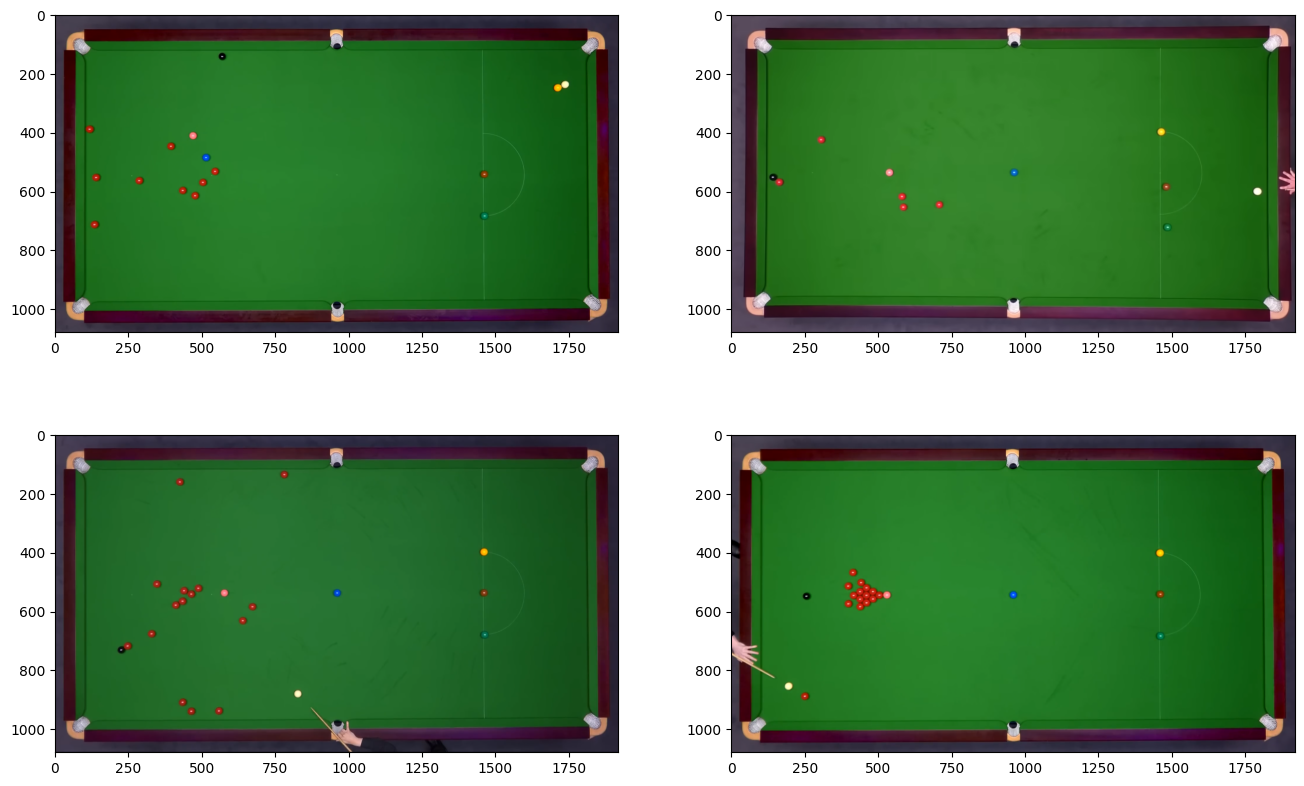

In [2]:
# zbiór danych
mcgill = cv2.imread('mcgill.png')
trump = cv2.imread('trump.png')
zhao = cv2.imread('zhao.png')
mcgill2 = cv2.imread('mcgill2.png')
# tu wyświetlone są wszystkie naraz w pomniejszeniu
# w eksperymentach staraj się wyświetlać je w dużym rozmiarze (albo używaj RoI)
_, axes = plt.subplots(2, 2, figsize=(16,10))
axes.ravel()[0].imshow(mcgill[..., ::-1])
axes.ravel()[1].imshow(trump[..., ::-1])
axes.ravel()[2].imshow(zhao[..., ::-1])
axes.ravel()[3].imshow(mcgill2[..., ::-1])